Python : 3.12.16 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 20:13:05) [MSC v.1942 64 bit (AMD64)]
PyTorch : 2.15.0+cpu
CUDA disponible : False


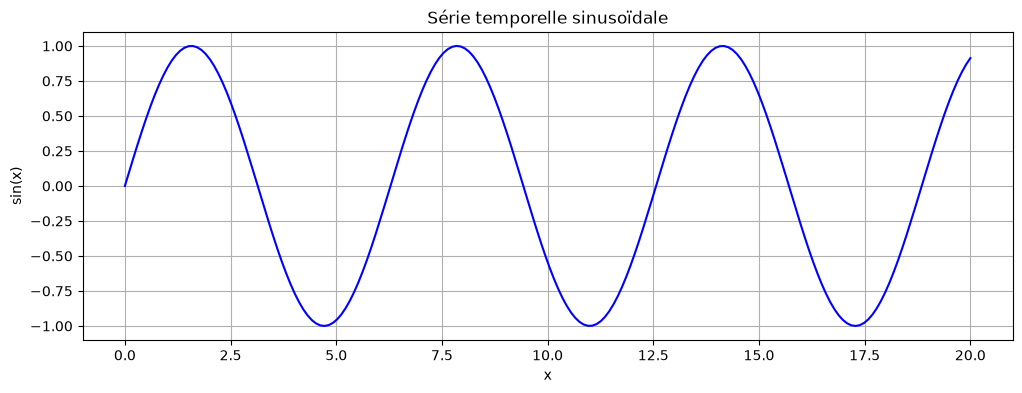

In [1]:
%matplotlib inline

import sys
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

print("Python :", sys.version)
print("PyTorch :", torch.__version__)
print("CUDA disponible :", torch.cuda.is_available())

periode = torch.linspace(0, 20, 200)
serie = torch.sin(periode)

plt.figure(figsize=(12, 4))
plt.plot(periode.numpy(), serie.numpy(), color="blue")
plt.title("Série temporelle sinusoïdale")
plt.xlabel("x")
plt.ylabel("sin(x)")
plt.grid(True)
plt.show()

## 2. Implémentation d'un RNN

Le RNN (Recurrent Neural Network) est un réseau de neurones
récurrent conçu pour traiter des données séquentielles.

Il traite les éléments d'une séquence successivement en
conservant un état caché qui contient les informations
des étapes précédentes.

Dans cette partie, nous utilisons un RNN pour prédire la
prochaine valeur de la série temporelle sinusoïdale à partir
des 10 valeurs précédentes.

In [5]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

# Génération de la série temporelle
periode = torch.linspace(0, 20, 200)
serie = torch.sin(periode)

longueur_sequence = 10

# Création des séquences
X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

X = X.unsqueeze(-1)
y = y.unsqueeze(-1)

# Séparation des données
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]

print("X_train :", X_train.shape)
print("y_train :", y_train.shape)
print("X_test  :", X_test.shape)
print("y_test  :", y_test.shape)

X_train : torch.Size([150, 10, 1])
y_train : torch.Size([150, 1])
X_test  : torch.Size([40, 10, 1])
y_test  : torch.Size([40, 1])


In [6]:
class SimpleRNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.rnn = nn.RNN(
            input_size=1,
            hidden_size=16,
            batch_first=True
        )

        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        etats, _ = self.rnn(x)
        dernier_etat = etats[:, -1, :]

        return self.sortie(dernier_etat)


modele_rnn = SimpleRNN()

print(modele_rnn)

SimpleRNN(
  (rnn): RNN(1, 16, batch_first=True)
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)


In [7]:
critere = nn.MSELoss()

optimiseur_rnn = torch.optim.Adam(
    modele_rnn.parameters(),
    lr=0.01
)

epochs = 300
historique_rnn = []

In [8]:
modele_rnn.train()

for epoch in range(epochs):

    predictions = modele_rnn(X_train)

    perte = critere(predictions, y_train)

    optimiseur_rnn.zero_grad()

    perte.backward()

    optimiseur_rnn.step()

    historique_rnn.append(perte.item())

    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch {epoch + 1:3d} | "
            f"Erreur : {perte.item():.6f}"
        )

Epoch  50 | Erreur : 0.001277
Epoch 100 | Erreur : 0.000504
Epoch 150 | Erreur : 0.000223
Epoch 200 | Erreur : 0.000103
Epoch 250 | Erreur : 0.000049
Epoch 300 | Erreur : 0.000025


In [9]:
modele_rnn.eval()

with torch.no_grad():

    predictions_rnn = modele_rnn(X_test)

    erreur_test_rnn = critere(
        predictions_rnn,
        y_test
    )

print(f"Erreur de test : {erreur_test_rnn.item():.6f}")
print(f"Valeur réelle : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions_rnn[0].item():.4f}")

Erreur de test : 0.000028
Valeur réelle : -0.3639
Valeur prédite : -0.3601


### 2.4. Visualisation des résultats

Nous représentons l'évolution de la fonction de perte
pendant l'entraînement ainsi que la comparaison entre
les valeurs réelles et les prédictions du RNN.

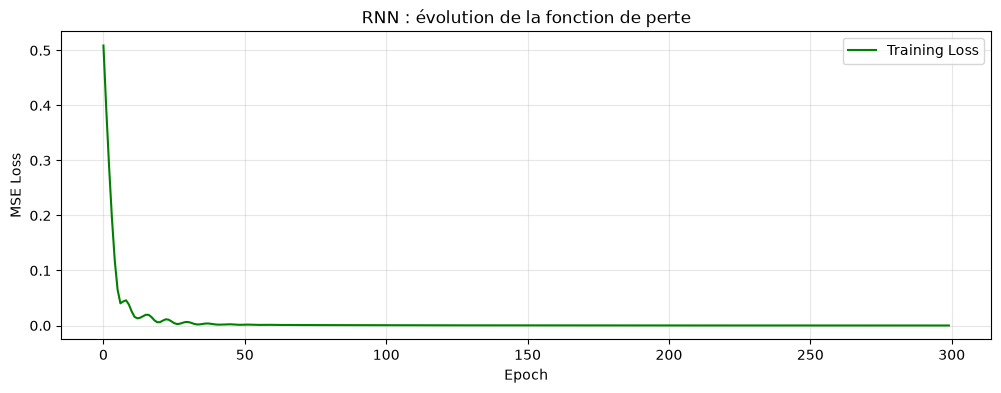

In [10]:
plt.figure(figsize=(12, 4))

plt.plot(
    historique_rnn,
    color="green",
    label="Training Loss"
)

plt.title("RNN : évolution de la fonction de perte")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

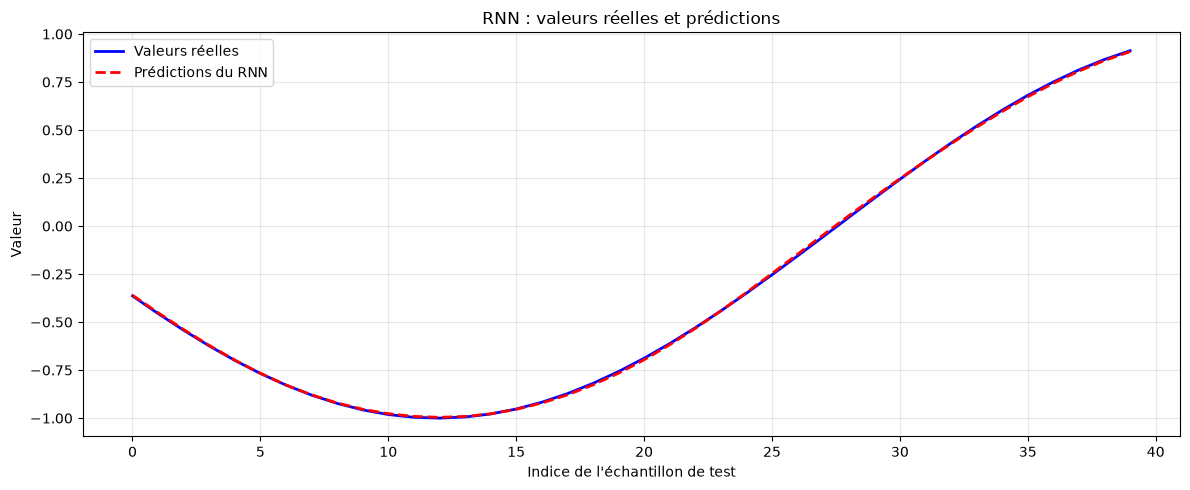

In [11]:
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)

valeurs_predites_rnn = (
    predictions_rnn.detach().cpu().numpy().reshape(-1)
)

plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites_rnn,
    label="Prédictions du RNN",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("RNN : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 2.5. Interprétation des résultats

Les résultats montrent que le RNN est capable d'apprendre
les dépendances temporelles de la série sinusoïdale.

La diminution de la fonction de perte indique que le modèle
améliore progressivement ses prédictions pendant l'entraînement.

Les valeurs prédites sont proches des valeurs réelles,
ce qui traduit une bonne capacité de généralisation sur
cette série temporelle simple.

Cependant, les RNN présentent certaines limites :

- Le traitement séquentiel des données.
- La difficulté de capturer les dépendances à long terme.
- Le problème de disparition du gradient (Vanishing Gradient).

Ces limitations motivent l'utilisation des architectures
LSTM et Transformer.

## 3. Implémentation du LSTM

Le LSTM (Long Short-Term Memory) est une architecture
de réseau de neurones récurrent conçue pour améliorer
la mémorisation des dépendances à long terme.

Contrairement au RNN classique, le LSTM dispose d'un
état de cellule et de trois portes principales :

- Forget Gate : sélectionne les informations à oublier.
- Input Gate : sélectionne les informations à mémoriser.
- Output Gate : contrôle les informations transmises en sortie.

Cette architecture permet de réduire le problème de
disparition du gradient rencontré dans les RNN classiques.

Nous utilisons le même jeu de données que celui du RNN
afin de comparer les performances des deux architectures.

In [12]:
class SimpleLSTM(nn.Module):

    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=16,
            num_layers=1,
            batch_first=True
        )

        self.sortie = nn.Linear(16, 1)

    def forward(self, x):

        etats, (h_final, c_final) = self.lstm(x)

        dernier_etat = etats[:, -1, :]

        return self.sortie(dernier_etat)


modele_lstm = SimpleLSTM()

print(modele_lstm)

SimpleLSTM(
  (lstm): LSTM(1, 16, batch_first=True)
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)


In [13]:
critere = nn.MSELoss()

optimiseur_lstm = torch.optim.Adam(
    modele_lstm.parameters(),
    lr=0.01
)

epochs = 300
historique_lstm = []

In [14]:
modele_lstm.train()

for epoch in range(epochs):

    predictions = modele_lstm(X_train)

    perte = critere(predictions, y_train)

    optimiseur_lstm.zero_grad()

    perte.backward()

    optimiseur_lstm.step()

    historique_lstm.append(perte.item())

    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch {epoch + 1:3d} | "
            f"Erreur : {perte.item():.6f}"
        )

Epoch  50 | Erreur : 0.002550
Epoch 100 | Erreur : 0.000239
Epoch 150 | Erreur : 0.000019
Epoch 200 | Erreur : 0.000014
Epoch 250 | Erreur : 0.000012
Epoch 300 | Erreur : 0.000010


In [15]:
modele_lstm.eval()

with torch.no_grad():

    predictions_lstm = modele_lstm(X_test)

    erreur_test_lstm = critere(
        predictions_lstm,
        y_test
    )

print(f"Erreur de test : {erreur_test_lstm.item():.6f}")
print(f"Valeur réelle : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions_lstm[0].item():.4f}")

Erreur de test : 0.000010
Valeur réelle : -0.3639
Valeur prédite : -0.3619


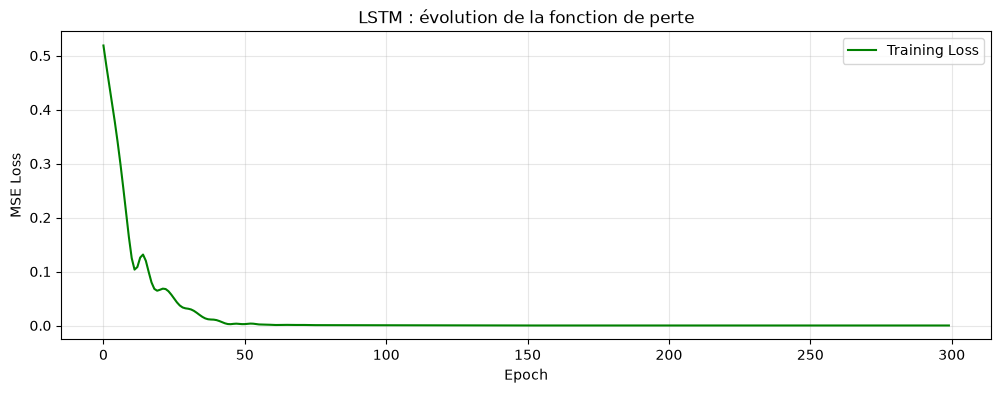

In [16]:
plt.figure(figsize=(12, 4))

plt.plot(
    historique_lstm,
    color="green",
    label="Training Loss"
)

plt.title("LSTM : évolution de la fonction de perte")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

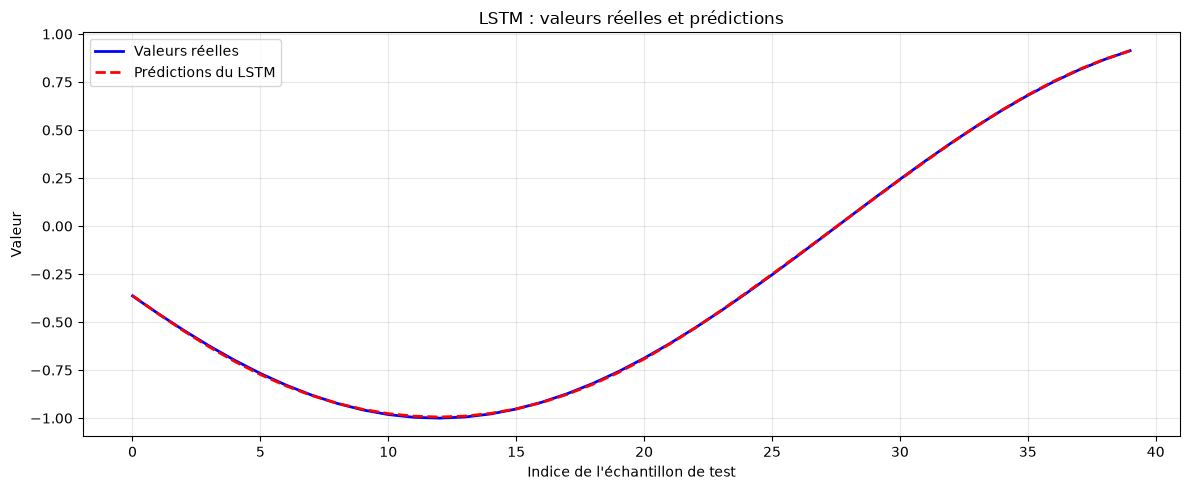

In [17]:
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)

valeurs_predites_lstm = (
    predictions_lstm.detach().cpu().numpy().reshape(-1)
)

plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites_lstm,
    label="Prédictions du LSTM",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("LSTM : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 3.5. Interprétation des résultats

Le modèle LSTM est capable d'apprendre les dépendances
temporelles de la série sinusoïdale.

La diminution progressive de la fonction de perte montre
que le modèle améliore ses prédictions durant l'entraînement.

Les valeurs prédites sont très proches des valeurs réelles.

Grâce à son mécanisme de portes et à son état de cellule,
le LSTM est conçu pour mieux conserver les informations
à long terme qu'un RNN classique.

Cependant, comme le RNN, le LSTM conserve un traitement
séquentiel des données, ce qui limite la parallélisation
des calculs.

Pour dépasser cette limitation, nous étudierons ensuite
l'architecture Transformer, basée sur le mécanisme d'attention.

In [18]:
import pandas as pd

comparaison = pd.DataFrame({
    "Modèle": ["RNN", "LSTM"],
    "MSE Test": [
        erreur_test_rnn.item(),
        erreur_test_lstm.item()
    ],
    "RMSE Test": [
        np.sqrt(erreur_test_rnn.item()),
        np.sqrt(erreur_test_lstm.item())
    ],
    "Nombre de paramètres": [
        sum(p.numel() for p in modele_rnn.parameters()),
        sum(p.numel() for p in modele_lstm.parameters())
    ]
})

comparaison

,Modèle,MSE Test,RMSE Test,Nombre de paramètres
0,RNN,0.000028,0.005256,321
1,LSTM,0.000010,0.003150,1233


## 4. Implémentation du Transformer

Le Transformer est une architecture de Deep Learning
introduite en 2017 dans l'article "Attention Is All You Need".

Contrairement aux RNN et LSTM, il repose principalement
sur le mécanisme d'attention, qui permet de traiter les
éléments d'une séquence en parallèle.

Les principaux composants du Transformer sont :

- Projection linéaire des entrées.
- Encodage positionnel.
- Multi-Head Self-Attention.
- Connexions résiduelles.
- Layer Normalization.
- Feed Forward Network.

Dans cette partie, nous utilisons un Transformer Encoder
pour prédire la prochaine valeur de la série sinusoïdale.

In [19]:
class MiniTransformer(nn.Module):

    def __init__(self, longueur_max=10):
        super().__init__()

        dimension = 16

        self.projection = nn.Linear(1, dimension)

        self.positions = nn.Embedding(
            longueur_max,
            dimension
        )

        couche = nn.TransformerEncoderLayer(
            d_model=dimension,
            nhead=2,
            dim_feedforward=32,
            dropout=0.0,
            batch_first=True
        )

        self.encodeur = nn.TransformerEncoder(
            couche,
            num_layers=1
        )

        self.sortie = nn.Linear(dimension, 1)

    def forward(self, x):

        longueur = x.size(1)

        x = self.projection(x)

        indices = torch.arange(
            longueur,
            device=x.device
        )

        positions = self.positions(indices)

        x = x + positions.unsqueeze(0)

        representations = self.encodeur(x)

        derniere_position = representations[:, -1, :]

        return self.sortie(derniere_position)


modele_transformer = MiniTransformer(
    longueur_max=longueur_sequence
)

print(modele_transformer)

MiniTransformer(
  (projection): Linear(in_features=1, out_features=16, bias=True)
  (positions): Embedding(10, 16)
  (encodeur): TransformerEncoder(
    (layers): ModuleList(
      (0): TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=16, out_features=16, bias=True)
        )
        (linear1): Linear(in_features=16, out_features=32, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
        (linear2): Linear(in_features=32, out_features=16, bias=True)
        (norm1): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.0, inplace=False)
        (dropout2): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)


In [21]:
critere = nn.MSELoss()

optimiseur_transformer = torch.optim.Adam(
    modele_transformer.parameters(),
    lr=0.01
)

epochs = 300
historique_transformer = []

In [22]:
modele_transformer.train()

for epoch in range(epochs):

    predictions = modele_transformer(X_train)

    perte = critere(predictions, y_train)

    optimiseur_transformer.zero_grad()

    perte.backward()

    optimiseur_transformer.step()

    historique_transformer.append(perte.item())

    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch {epoch + 1:3d} | "
            f"Erreur : {perte.item():.6f}"
        )

Epoch  50 | Erreur : 0.000699
Epoch 100 | Erreur : 0.000504
Epoch 150 | Erreur : 0.001928
Epoch 200 | Erreur : 0.000108
Epoch 250 | Erreur : 0.000060
Epoch 300 | Erreur : 0.000037


In [23]:
modele_transformer.eval()

with torch.no_grad():

    predictions_transformer = modele_transformer(X_test)

    erreur_test_transformer = critere(
        predictions_transformer,
        y_test
    )

print(f"Erreur de test : {erreur_test_transformer.item():.6f}")
print(f"Valeur réelle : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions_transformer[0].item():.4f}")

Erreur de test : 0.000053
Valeur réelle : -0.3639
Valeur prédite : -0.3693


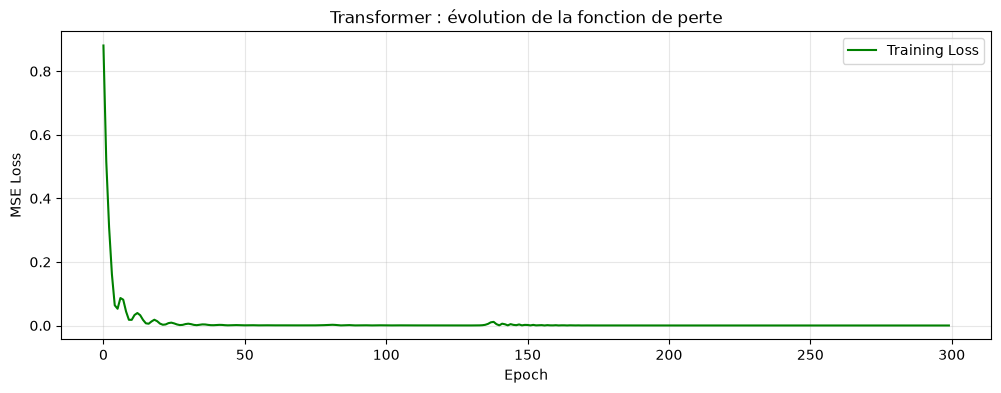

In [24]:
plt.figure(figsize=(12, 4))

plt.plot(
    historique_transformer,
    color="green",
    label="Training Loss"
)

plt.title("Transformer : évolution de la fonction de perte")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

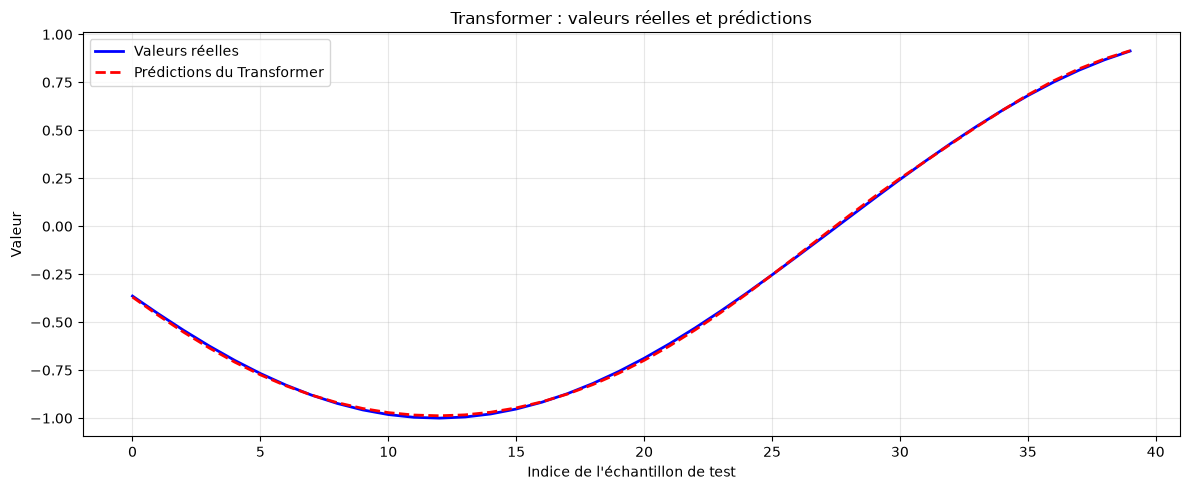

In [25]:
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)

valeurs_predites_transformer = (
    predictions_transformer.detach().cpu().numpy().reshape(-1)
)

plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites_transformer,
    label="Prédictions du Transformer",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("Transformer : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Interprétation des résultats

Les résultats montrent que le Transformer est capable
d'apprendre les dépendances temporelles de la série
sinusoïdale grâce au mécanisme de Self-Attention.

La diminution de la fonction de perte indique une
amélioration progressive des prédictions.

Contrairement aux RNN et LSTM, le Transformer ne repose
pas sur un traitement récurrent des données.

Ses principaux avantages sont :

- Le traitement parallèle des éléments de la séquence.
- La capture des relations entre les éléments éloignés.
- L'utilisation de plusieurs têtes d'attention.
- La prise en compte de l'ordre des éléments grâce
  aux embeddings positionnels.

Cependant, le mécanisme d'attention classique présente
un coût de calcul quadratique par rapport à la longueur
de la séquence.

## 5. Étude comparative : RNN, LSTM et Transformer

Dans cette section, nous comparons les trois architectures
en utilisant le même jeu de données et les mêmes paramètres
d'entraînement.

Les critères de comparaison sont :

- MSE : erreur quadratique moyenne.
- RMSE : racine de l'erreur quadratique moyenne.
- MAE : erreur absolue moyenne.
- Nombre de paramètres du modèle.

In [26]:
import pandas as pd

comparaison = pd.DataFrame({

    "Modèle": ["RNN", "LSTM", "Transformer"],

    "MSE Test": [
        erreur_test_rnn.item(),
        erreur_test_lstm.item(),
        erreur_test_transformer.item()
    ],

    "RMSE Test": [
        np.sqrt(erreur_test_rnn.item()),
        np.sqrt(erreur_test_lstm.item()),
        np.sqrt(erreur_test_transformer.item())
    ],

    "MAE Test": [
        torch.mean(torch.abs(predictions_rnn - y_test)).item(),
        torch.mean(torch.abs(predictions_lstm - y_test)).item(),
        torch.mean(torch.abs(predictions_transformer - y_test)).item()
    ],

    "Nombre de paramètres": [
        sum(p.numel() for p in modele_rnn.parameters()),
        sum(p.numel() for p in modele_lstm.parameters()),
        sum(p.numel() for p in modele_transformer.parameters())
    ]
})

comparaison.style.format({
    "MSE Test": "{:.8f}",
    "RMSE Test": "{:.6f}",
    "MAE Test": "{:.6f}"
})

,Modèle,MSE Test,RMSE Test,MAE Test,Nombre de paramètres
0,RNN,0.00002763,0.005256,0.004562,321
1,LSTM,0.00000992,0.003150,0.002636,1233
2,Transformer,0.00005281,0.007267,0.006346,2433


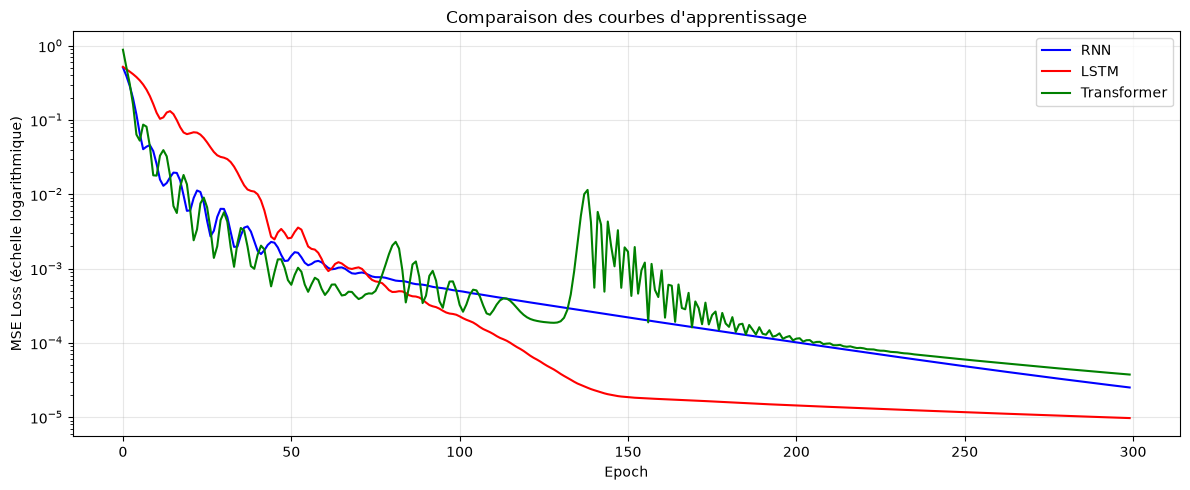

In [27]:
plt.figure(figsize=(12, 5))

plt.plot(historique_rnn, label="RNN", color="blue")
plt.plot(historique_lstm, label="LSTM", color="red")
plt.plot(historique_transformer, label="Transformer", color="green")

plt.yscale("log")

plt.title("Comparaison des courbes d'apprentissage")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss (échelle logarithmique)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

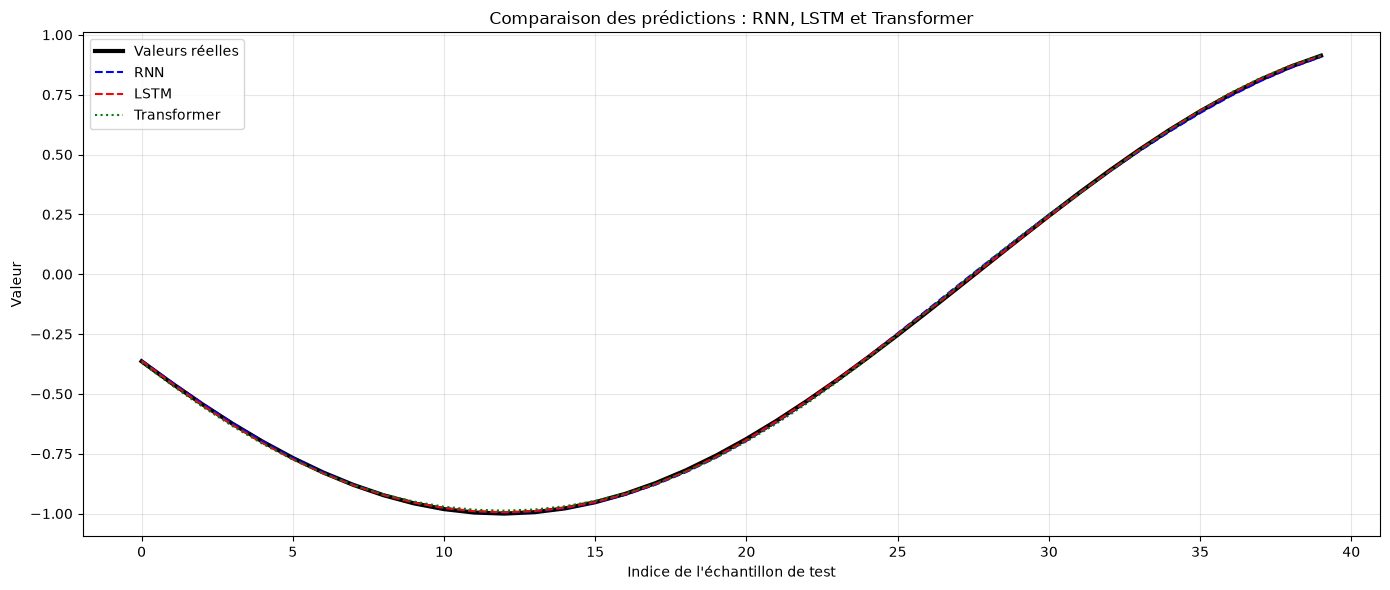

In [28]:
plt.figure(figsize=(14, 6))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="black",
    linewidth=3
)

plt.plot(
    valeurs_predites_rnn,
    label="RNN",
    color="blue",
    linestyle="--"
)

plt.plot(
    valeurs_predites_lstm,
    label="LSTM",
    color="red",
    linestyle="--"
)

plt.plot(
    valeurs_predites_transformer,
    label="Transformer",
    color="green",
    linestyle=":"
)

plt.title("Comparaison des prédictions : RNN, LSTM et Transformer")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Comparaison des architectures

| Critère | RNN | LSTM | Transformer |
|---|---|---|---|
| Mécanisme principal | Récurrence | Récurrence avec portes | Self-Attention |
| Traitement | Séquentiel | Séquentiel | Parallèle |
| Mémoire | État caché | État caché et état de cellule | Attention |
| Dépendances longues | Limitées | Améliorées | Directes |
| Information de position | Implicite | Implicite | Explicite dans notre modèle |
| Vanishing Gradient | Sensible | Atténué | Pas de chaîne récurrente temporelle |

Le choix de l'architecture dépend de la nature des données,
de la complexité du problème et des ressources disponibles.

Un Transformer n'est pas nécessairement plus performant
qu'un RNN ou un LSTM sur une série temporelle simple.